CS 6625 – Machine Learning-Based Phishing URL Detection
Student Name:Nichols
Week 2: Dataset Exploration

In [1]:
!pip install -q ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

In [3]:
phiusiil = fetch_ucirepo(id=967)

X = phiusiil.data.features.copy()
y = phiusiil.data.targets.squeeze().copy()

In [4]:
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (235795, 54)
Target shape: (235795,)


In [5]:
pd.set_option("display.max_columns", 12)

X.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,...,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,...,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,...,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,...,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,...,244,15,34,72,1,85


In [6]:
y.head()

,label
0,1
1,1
2,1
3,1
4,1


In [7]:
print(X.columns.tolist())

['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [8]:
print(y.value_counts())
##0 = phishing
##1 = legitimate

label
1    134850
0    100945
Name: count, dtype: int64


In [9]:
class_counts = y.value_counts().sort_index()

print(class_counts)

label
0    100945
1    134850
Name: count, dtype: int64


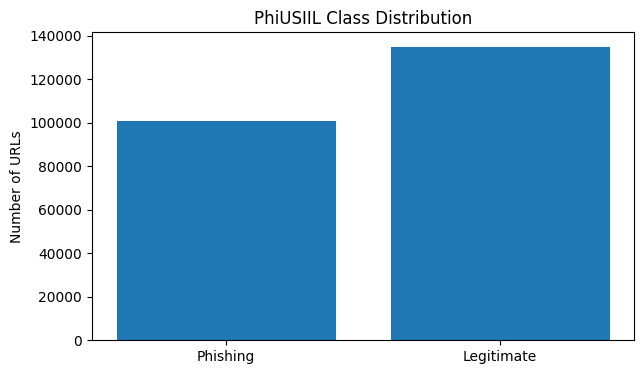

In [10]:
labels = ["Phishing", "Legitimate"]

counts = [
    class_counts.loc[0],
    class_counts.loc[1]
]

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)

plt.ylabel("Number of URLs")
plt.title("PhiUSIIL Class Distribution")

plt.show()

In [11]:
print(X.dtypes.value_counts())

int64      40
float64    10
object      4
Name: count, dtype: int64


In [12]:
numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

non_numeric_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:", len(numeric_columns))
print("Non-numeric columns:", len(non_numeric_columns))

print(non_numeric_columns)

Numeric columns: 50
Non-numeric columns: 4
['URL', 'Domain', 'TLD', 'Title']


In [13]:
missing_total = X.isna().sum().sum()

print(
    "Total missing feature values:",
    missing_total
)

Total missing feature values: 0


In [14]:
X.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,...,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,...,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,...,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,...,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,...,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000


In [15]:
X.select_dtypes(
    include=np.number
).describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,0.090824
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,13.000000
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,10.000000
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000


In [16]:
analysis_df = X[
    ["URLLength", "DomainLength", "IsDomainIP"]
].copy()

analysis_df["Label"] = y.values

In [17]:
analysis_df.groupby(
    "Label"
)["URLLength"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Label,,,,,
0,100945,45.720293,34.0,13,6097
1,134850,26.228610,26.0,15,57


In [18]:
analysis_df.groupby(
    "Label"
)["DomainLength"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Label,,,,
0,24.465144,22.0,4,110
1,19.228610,19.0,8,50


In [19]:
pd.crosstab(
    analysis_df["Label"],
    analysis_df["IsDomainIP"],
    normalize="index"
)

IsDomainIP,0,1
Label,,
0,0.99368,0.00632
1,1.00000,0.00000


In [20]:
phishing_target = (y == 0).astype(int)

In [21]:
print(
    phishing_target.value_counts()
)

label
0    134850
1    100945
Name: count, dtype: int64


In [22]:
numeric_df = X.select_dtypes(
    include=np.number
).copy()

numeric_df["Phishing"] = phishing_target.values

In [23]:
correlations = (
    numeric_df.corr(numeric_only=True)["Phishing"]
    .drop("Phishing")
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

correlations.head(15)

,Phishing
URLSimilarityIndex,-0.860358
HasSocialNet,-0.784255
HasCopyrightInfo,-0.743358
HasDescription,-0.690232
IsHTTPS,-0.609132
DomainTitleMatchScore,-0.584905
HasSubmitButton,-0.578561
IsResponsive,-0.548608
URLTitleMatchScore,-0.539419
SpacialCharRatioInURL,0.533537


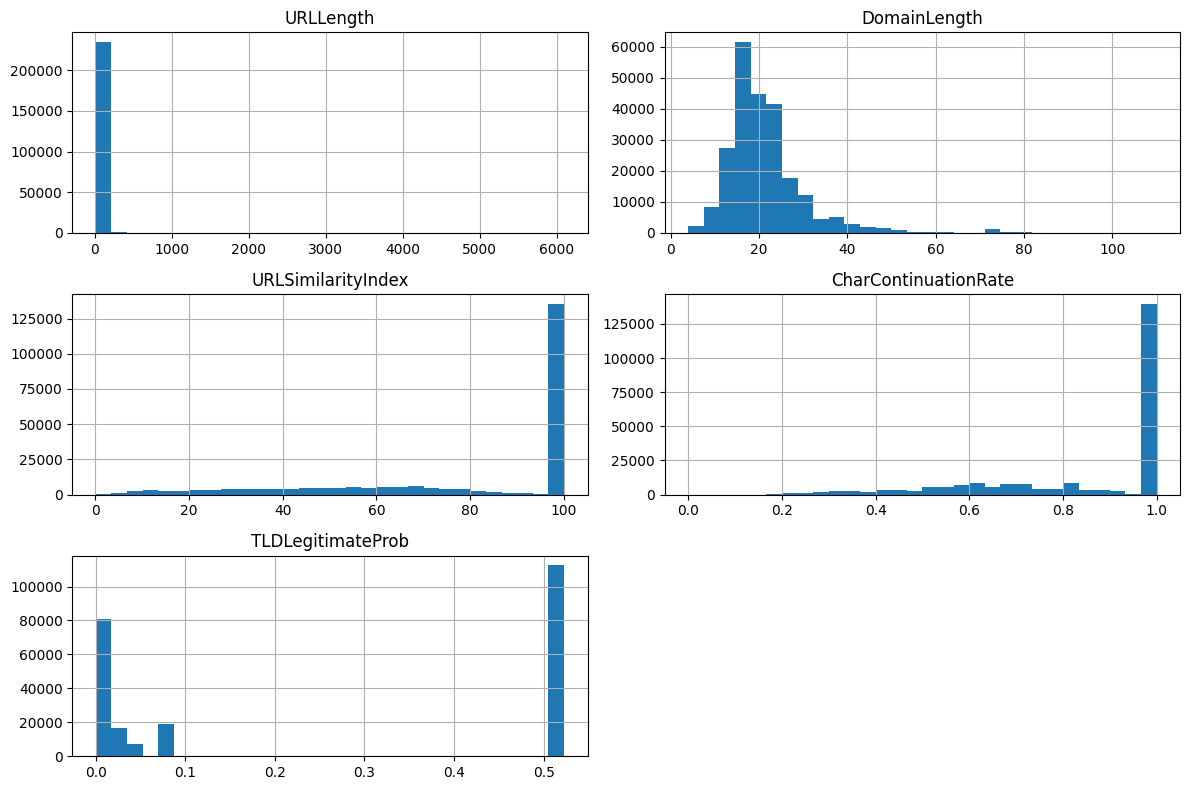

In [24]:
selected_features = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb"
]

X[selected_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

Week 3: Data Preparation and Train/Test Split

In [25]:
phiusiil = fetch_ucirepo(id=967)

X_raw = phiusiil.data.features.copy()
y_original = phiusiil.data.targets.squeeze().copy()

In [26]:
print(X_raw.shape)
print(y_original.shape)

(235795, 54)
(235795,)


In [27]:
y = (y_original == 0).astype(int)

y.name = "Phishing"

In [28]:
print(y.value_counts())

Phishing
0    134850
1    100945
Name: count, dtype: int64


In [29]:
X = X_raw.select_dtypes(
    include=np.number
).copy()

In [30]:
print(X.shape)

print(X.columns.tolist())

(235795, 50)
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [31]:
print(
    "Number of X rows:",
    len(X)
)

print(
    "Number of y values:",
    len(y)
)

Number of X rows: 235795
Number of y values: 235795


In [32]:
print(
    "Missing values:",
    X.isna().sum().sum()
)

Missing values: 0


In [33]:
selected_features = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb"
]

In [34]:
X[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907


In [35]:
analysis_df = X[
    selected_features
].copy()

analysis_df["Phishing"] = y.values

In [36]:
analysis_df.groupby(
    "Phishing"
)[selected_features].mean().T

Phishing,0,1
URLLength,26.228610,45.720293
DomainLength,19.228610,24.465144
URLSimilarityIndex,100.000000,49.616973
CharContinuationRate,0.933176,0.728395
TLDLegitimateProb,0.281625,0.232099


In [37]:
legitimate_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 0,
    "URLLength"
]

phishing_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 1,
    "URLLength"
]

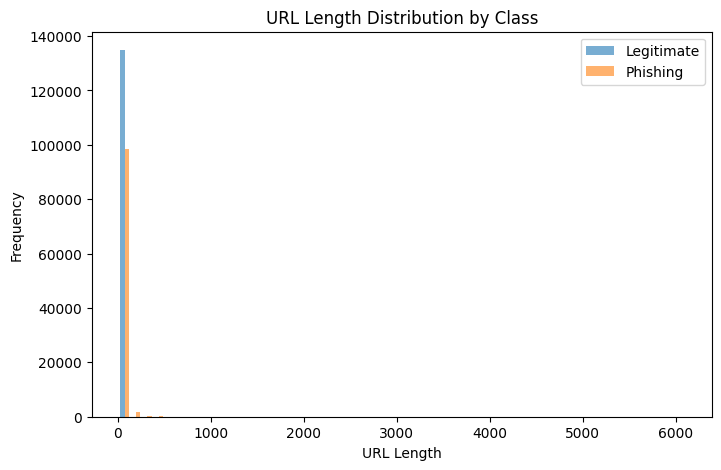

In [38]:
plt.figure(figsize=(8, 5))

plt.hist(
    [
        legitimate_url_length,
        phishing_url_length
    ],
    bins=50,
    label=[
        "Legitimate",
        "Phishing"
    ],
    alpha=0.6
)

plt.xlabel("URL Length")
plt.ylabel("Frequency")

plt.title(
    "URL Length Distribution by Class"
)

plt.legend()

plt.show()

Part 1 — Prepared Data

In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [41]:
print(
    "X_train:",
    X_train.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_test:",
    y_test.shape
)

X_train: (188636, 50)
X_test: (47159, 50)
y_train: (188636,)
y_test: (47159,)


In [42]:
print(
    "Full dataset:"
)

print(
    y.value_counts(
        normalize=True
    )
)

Full dataset:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [43]:
print(
    "Training:"
)

print(
    y_train.value_counts(
        normalize=True
    )
)

Training:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [44]:
print(
    "Testing:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)

Testing:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [45]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [46]:
print(
    X_train.index.equals(
        X_train2.index
    )
)

print(
    X_test.index.equals(
        X_test2.index
    )
)

True
True


In [47]:
_, X_test_temp, _, y_test_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [48]:
print(
    "Stratified:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)

print(
    "Not stratified:"
)

print(
    y_test_temp.value_counts(
        normalize=True
    )
)

Stratified:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64
Not stratified:
Phishing
0    0.573273
1    0.426727
Name: proportion, dtype: float64


In [49]:
for seed in [
    1,
    21,
    42,
    100
]:

    _, X_temp, _, y_temp = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    print(
        seed,
        y_temp.mean()
    )

1 0.42810492164804176
21 0.42810492164804176
42 0.42810492164804176
100 0.42810492164804176


Week 4: Logistic Regression and Classification Metrics

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [51]:
lr_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])

In [52]:
lr_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=2000))])

In [53]:
lr_pred = lr_model.predict(
    X_test
)

In [54]:
print(
    lr_pred[:20]
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [55]:
print(
    y_test.iloc[:20].to_numpy()
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [56]:
lr_prob = lr_model.predict_proba(
    X_test
)[:, 1]

In [57]:
print(
    lr_prob[:10]
)

[7.76971563e-07 9.99999753e-01 1.85108133e-04 1.00000000e+00
 8.82577634e-05 3.54717718e-07 9.99711349e-01 9.99999574e-01
 6.63741195e-14 6.65616758e-09]


In [58]:
probability_preview = pd.DataFrame({
    "Actual":
        y_test.iloc[:10].to_numpy(),

    "Predicted":
        lr_pred[:10],

    "Phishing Probability":
        lr_prob[:10]
})

probability_preview

,Actual,Predicted,Phishing Probability
0,0,0,7.769716e-07
1,1,1,9.999998e-01
2,0,0,1.851081e-04
3,1,1,1.000000e+00
4,0,0,8.825776e-05
5,0,0,3.547177e-07
6,1,1,9.997113e-01
7,1,1,9.999996e-01
8,0,0,6.637412e-14
9,0,0,6.656168e-09


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [60]:
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred
)

lr_recall = recall_score(
    y_test,
    lr_pred
)

lr_f1 = f1_score(
    y_test,
    lr_pred
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

In [61]:
print(
    f"Accuracy : {lr_accuracy:.4f}"
)

print(
    f"Precision: {lr_precision:.4f}"
)

print(
    f"Recall   : {lr_recall:.4f}"
)

print(
    f"F1-score : {lr_f1:.4f}"
)

print(
    f"ROC-AUC  : {lr_auc:.4f}"
)

Accuracy : 0.9999
Precision: 1.0000
Recall   : 0.9998
F1-score : 0.9999
ROC-AUC  : 1.0000


In [62]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [63]:
cm = confusion_matrix(
    y_test,
    lr_pred
)

print(cm)

[[26970     0]
 [    5 20184]]


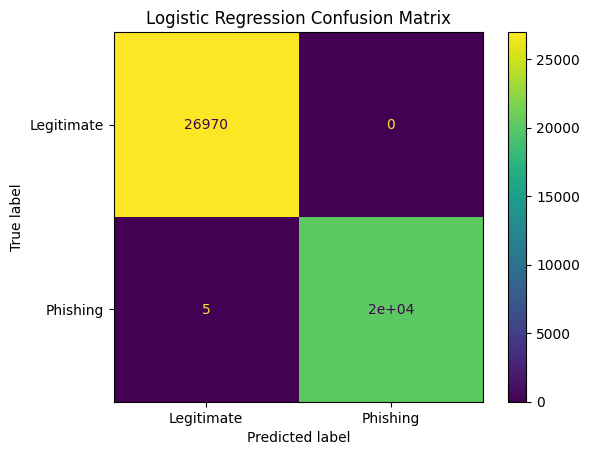

In [64]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

In [65]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        lr_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



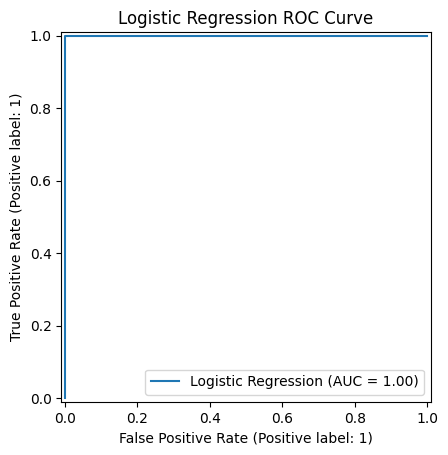

In [66]:
from sklearn.metrics import (
    RocCurveDisplay
)

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.show()

In [67]:
model_results = pd.DataFrame([
    {
        "Model":
            "Logistic Regression",

        "Accuracy":
            lr_accuracy,

        "Precision":
            lr_precision,

        "Recall":
            lr_recall,

        "F1-score":
            lr_f1,

        "ROC-AUC":
            lr_auc
    }
])

model_results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.999894,1.0,0.999752,0.999876,1.0


In [68]:
def evaluate_threshold(
    threshold
):

    predictions = (
        lr_prob >= threshold
    ).astype(int)

    return {
        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                y_test,
                predictions
            ),

        "Precision":
            precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "F1-score":
            f1_score(
                y_test,
                predictions,
                zero_division=0
            )
    }

In [69]:
threshold_results = pd.DataFrame([
    evaluate_threshold(0.30),
    evaluate_threshold(0.50),
    evaluate_threshold(0.70)
])

threshold_results

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.999979,1.0,0.999950,0.999975
1,0.5,0.999894,1.0,0.999752,0.999876
2,0.7,0.999788,1.0,0.999505,0.999752


In [70]:
classifier = lr_model.named_steps[
    "classifier"
]

In [71]:
coefficient_df = pd.DataFrame({
    "Feature":
        X_train.columns,

    "Coefficient":
        classifier.coef_[0]
})

In [72]:
coefficient_df[
    "Absolute_Coefficient"
] = coefficient_df[
    "Coefficient"
].abs()

In [73]:
coefficient_df = (
    coefficient_df
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)

coefficient_df.head(15)

,Feature,Coefficient,Absolute_Coefficient
3,URLSimilarityIndex,-6.956245,6.956245
21,IsHTTPS,-3.879599,3.879599
20,SpacialCharRatioInURL,1.887845,1.887845
13,LetterRatioInURL,1.774712,1.774712
46,NoOfJS,-1.770485,1.770485
36,HasSocialNet,-1.478811,1.478811
47,NoOfSelfRef,-1.383850,1.383850
44,NoOfImage,-1.261538,1.261538
8,NoOfSubDomain,-1.259081,1.259081
15,DegitRatioInURL,1.233362,1.233362


In [74]:
lr_balanced = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

In [75]:
lr_balanced.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [76]:
balanced_pred = (
    lr_balanced.predict(
        X_test
    )
)

In [77]:
print(
    "Default recall:",
    recall_score(
        y_test,
        lr_pred
    )
)

print(
    "Balanced recall:",
    recall_score(
        y_test,
        balanced_pred
    )
)

Default recall: 0.9997523403833771
Balanced recall: 0.9998018723067017


Week 5: Decision Tree Phishing Detection

Part 2 — Train a Decision Tree

In [78]:
from sklearn.tree import DecisionTreeClassifier

In [79]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

In [80]:
dt_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [81]:
dt_pred = dt_model.predict(
    X_test
)

In [82]:
print(
    dt_pred[:20]
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [83]:
print(
    dt_model.get_depth()
)

4


In [84]:
print(
    dt_model.get_n_leaves()
)

5


Part 3 — Evaluate the Model

In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [86]:
dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

dt_precision = precision_score(
    y_test,
    dt_pred
)

dt_recall = recall_score(
    y_test,
    dt_pred
)

dt_f1 = f1_score(
    y_test,
    dt_pred
)

In [87]:
print(
    f"Accuracy : {dt_accuracy:.4f}"
)

print(
    f"Precision: {dt_precision:.4f}"
)

print(
    f"Recall   : {dt_recall:.4f}"
)

print(
    f"F1-score : {dt_f1:.4f}"
)

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


In [88]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [89]:
cm = confusion_matrix(
    y_test,
    dt_pred
)

print(cm)

[[26970     0]
 [    0 20189]]


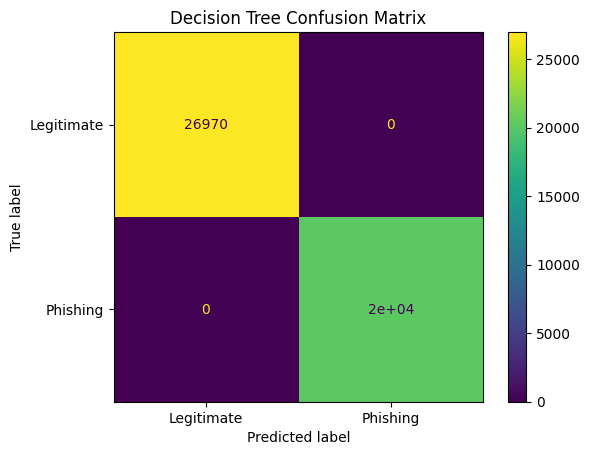

In [90]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

In [91]:
train_accuracy = dt_model.score(
    X_train,
    y_train
)

test_accuracy = dt_model.score(
    X_test,
    y_test
)

print(
    "Training accuracy:",
    train_accuracy
)

print(
    "Testing accuracy:",
    test_accuracy
)

Training accuracy: 1.0
Testing accuracy: 1.0


In [92]:
print(
    "X_train:",
    X_train.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_test:",
    y_test.shape
)

X_train: (188636, 50)
X_test: (47159, 50)
y_train: (188636,)
y_test: (47159,)


In [93]:
for depth in [
    1,
    3,
    5,
    10,
    20,
    None
]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    print(
        depth,
        "Train:",
        model.score(
            X_train,
            y_train
        ),
        "Test:",
        model.score(
            X_test,
            y_test
        )
    )

1 Train: 0.9966390296655994 Test: 0.9967768612566
3 Train: 0.999989397569923 Test: 1.0
5 Train: 1.0 Test: 1.0
10 Train: 1.0 Test: 1.0
20 Train: 1.0 Test: 1.0
None Train: 1.0 Test: 1.0


In [94]:
from sklearn.tree import plot_tree

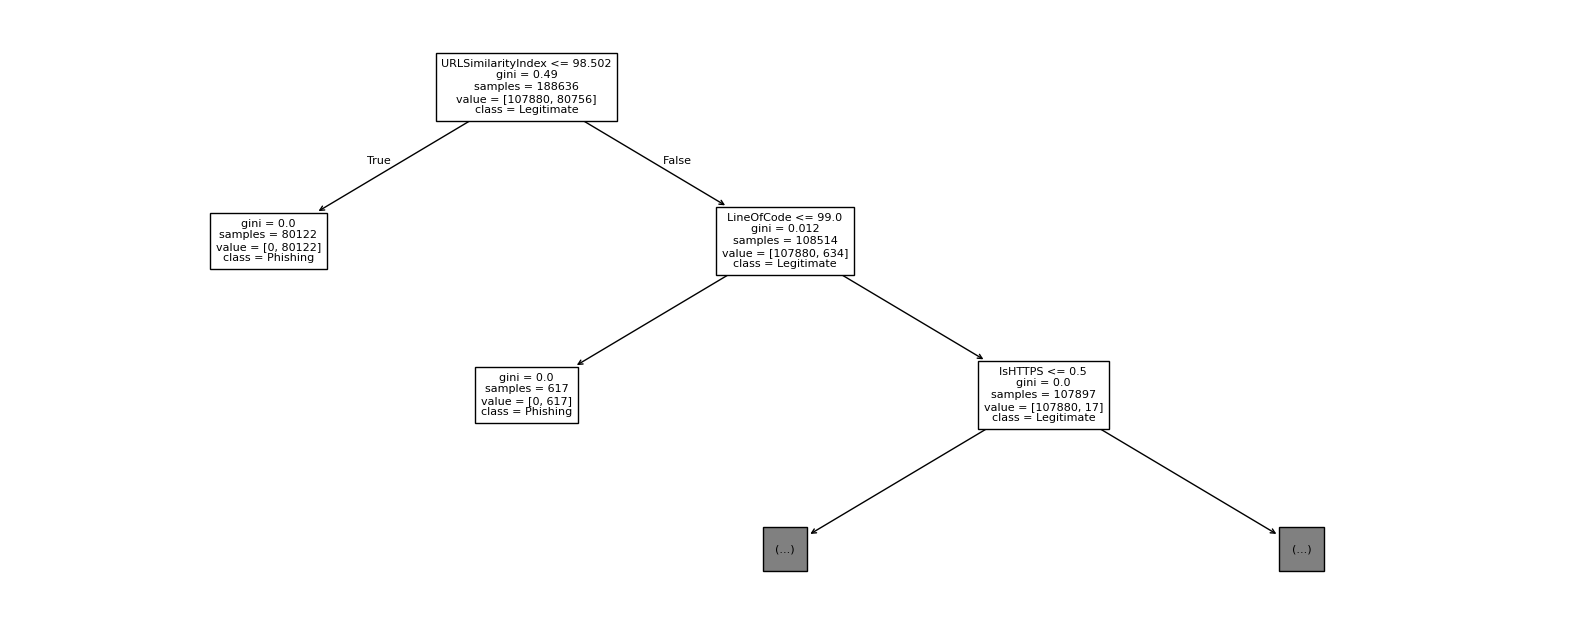

In [95]:
plt.figure(
    figsize=(20, 8)
)

plot_tree(
    dt_model,
    feature_names=
        X_train.columns,

    class_names=[
        "Legitimate",
        "Phishing"
    ],

    max_depth=2,

    filled=False,

    fontsize=8
)

plt.show()

In [96]:
from sklearn.tree import export_text

In [97]:
rules = export_text(
    dt_model,
    feature_names=
        list(
            X_train.columns
        ),
    max_depth=3
)

print(rules)

|--- URLSimilarityIndex <= 98.50
|   |--- class: 1
|--- URLSimilarityIndex >  98.50
|   |--- LineOfCode <= 99.00
|   |   |--- class: 1
|   |--- LineOfCode >  99.00
|   |   |--- IsHTTPS <= 0.50
|   |   |   |--- class: 1
|   |   |--- IsHTTPS >  0.50
|   |   |   |--- NoOfSubDomain <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- NoOfSubDomain >  0.50
|   |   |   |   |--- class: 0




Homework 5:

2.What does a false negative mean in this phishing-detection project?

A phishing URL was incorrectly classified as legitimate. Possible consequences are Phishing page escape detection, user may enter credentials, malware could be delivered, organizational access could be compromised.

Part 5 — Short Analysis

Question 1: What is a Decision Tree?

	A Decision Tree is a supervised machine-learning algorithm that makes predictions by repeatedly asking questions about feature values.

Question 2: What does: max_depth=5 control?

It controls how deep the Decision Tree is allowed to grow. Setting this threshold limits the model complexity by restricting it to a maximum of 5 layers of decisions.

Question 3: Why might a very deep Decision Tree overfit the training data?

	A very deep Decision Tree may create rules for small groups or individual observations. It also has the capacity to create excessive amount of split.
	Reasons why this happens:
		Memorizing Noise and Outliers
		Overly Specific Rules
		Lack of Regularization or stopping rules
		High Variance


Question 4: Which metric do you think is especially important for phishing detection:
•	Accuracy
•	Precision
•	Recall
•	F1-score
Explain your choice.

There may be more than one reasonable answer if your explanation is correct.
All four metrics are important for evaluating the performance of a machine learning model. However, I believe F1-score is especially important for phishing detection because it balances precision and recall, particularly when dealing with imbalanced datasets.
•	Accuracy: Measures the proportion of correct predictions, including true positives and true negatives, out of all predictions. It is useful for balanced datasets but can be misleading when classes are heavily imbalanced.
•	Precision: Measures how many emails predicted as phishing are actually phishing. High precision means fewer false alarms, reducing the chances of legitimate emails being incorrectly flagged.
•	Recall: Measures how many actual phishing emails the model correctly identifies. High recall means fewer phishing emails go undetected.
•	F1-score: Combines precision and recall into a single metric, making it useful for evaluating models with imbalanced datasets. A higher F1-score indicates a better balance between detecting phishing emails and minimizing false alarms.
Overall, I would choose F1-score because phishing detection requires identifying malicious emails while minimizing the number of legitimate emails incorrectly classified as phishing.


